<a href="https://colab.research.google.com/github/Serahverg-8/scratch-ml/blob/main/micrograd_nextpart.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Understanding NN with micrograd recreation.

In [46]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
def f(x):
  return 3*x**2 - 4*x +5

In [ ]:
f(3.0)

20.0

In [ ]:
xs = np.arange(-5,5,0.25)

In [ ]:
y=f(xs)

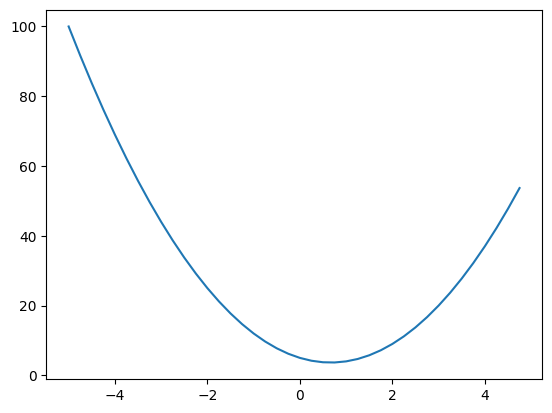

In [ ]:
plt.plot(xs,y)

### Derivative: how does the function change if we augment the value by a very small increment.  f(x) vs f(x+h)

In [ ]:
h=0.00000001
x=2/3
f(x)

3.666666666666667

In [ ]:
f(x+h)

3.666666666666667

In [ ]:
#slope = rise/run ( change in y by change in x)
(f(x+h) - f(x)) / h

0.0

In [ ]:
#when x=2/3 the slop is 0. small change doesnt effect y

In [ ]:
#another example:
a = 3.0
b = -2.0
c = 1.0
d = a*b + c
d


-5.0

In [ ]:
h= 0.00001
b=b+h

In [ ]:
d1 = a*b + c

In [ ]:
print(d,d1)

-5.0 -4.99996


In [ ]:
(d1-d)/h

4.000000000026205

# class for  arithmetic ops

In [114]:
class Value:

  def __init__(self, data, _children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"

  def __add__(self, other):
    other=other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')

    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward

    return out

  def __mul__(self, other):
    other=other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')

    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward

    return out

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')

    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward

    return out

  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')

  def backward(self):

    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)

    self.grad = 1.0
    for node in reversed(topo):
      node._backward()


In [ ]:
a=Value(5,label='a')
b=Value(10,label='b')
c=Value(-1,label='c')

In [ ]:
d = a + b * c
d.label = 'd'

In [ ]:
d._prev

{Value(data=-10), Value(data=5)}

In [ ]:
d._op

'+'

In [ ]:
d.label

'd'

## VISUALISE

In [62]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

In [ ]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d * f; L.label = 'L'
L

Value(data=-8.0)

In [ ]:
L.grad = 1
#base case. its like derivative of the function L wrt to h. = ((L+h) -L )/h =1 . base case from what we start with

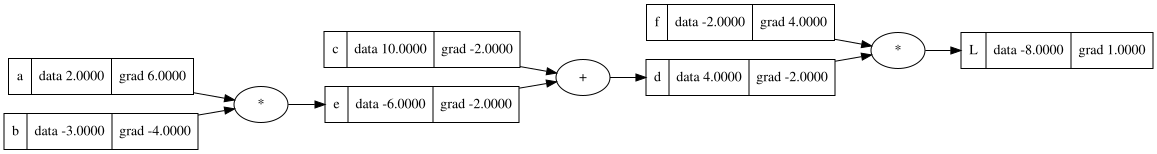

In [ ]:
draw_dot(L)

In [ ]:
#dL/dc so the impact of h being added to c in d expression. and the effect of h added to d in th eL expression
# dl/dc = dd/dc * dl/dd

In [ ]:
def lol():

  h = 0.001

  a = Value(2.0, label='a')
  b = Value(-3.0, label='b')
  c = Value(10.0, label='c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2.0, label='f')
  L = d * f; L.label = 'L'
  L1 = L.data
  print(a)

  a = Value(2.0, label='a')
  b = Value(-3.0, label='b')
  c = Value(10.0, label='c')
  a.data += h
  e = a*b; e.label = 'e'

  d = e + c; d.label = 'd'
  f = Value(-2.0, label='f')

  L = d * f; L.label = 'L'
  L2 = L.data

  print(a)
  print((L2 - L1)/h)

lol()

Value(data=2.0)
Value(data=2.001)
6.000000000000227


In [ ]:
d.grad = -2.0

In [ ]:
f.grad = 4.0

In [ ]:
c.grad = e.grad = -2.0

In [ ]:
a.grad = 6.0

In [ ]:
b.grad = -4.0

So how do we impact the value of L . Lets say we want to increase the vlaue of L ( less negative) we add a small step in the direction of the gradient. so a+h b+h c+h ...etc


## Doing the same with a neuron

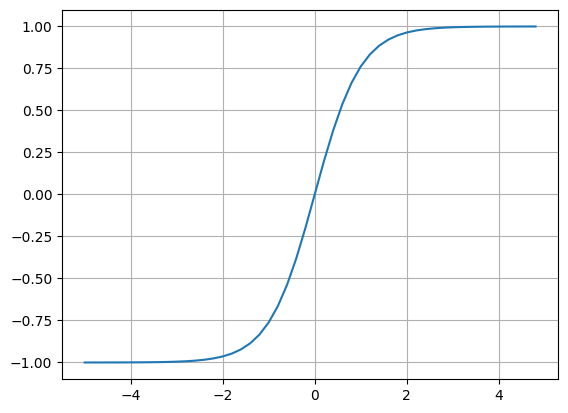

In [ ]:
#tanh activation funciton for example.  function lies between [-1 to 1]
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid();

In [ ]:
#One activation function  --> input to the intermediate layer

# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# Z = x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'

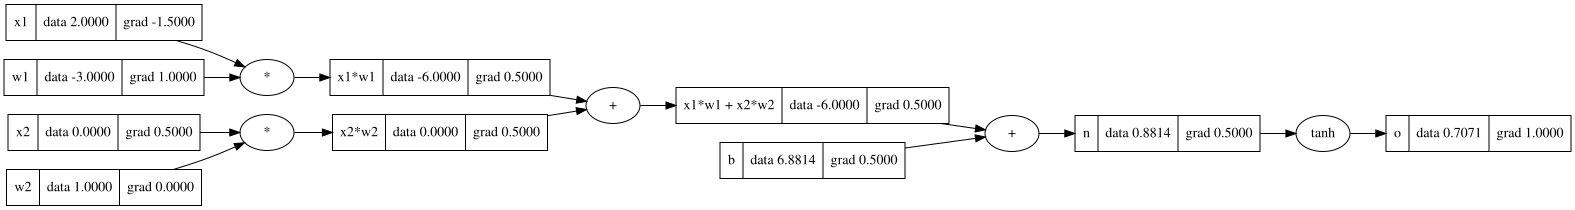

In [ ]:
draw_dot(o)

In [ ]:
o.grad = 1.0

In [ ]:
o.data

0.7071067811865476

In [ ]:
#derivative of  o=tanh(n) ;do/dn = 1-tanh(n)**2 = 1 - o.data**2

1-o.data**2


0.4999999999999999

In [ ]:
n.grad=0.5

In [ ]:
b.grad = x1w1x2w2.grad =  x1w1.grad = x2w2.grad  = 0.5

In [ ]:
x1.grad = -3.0 * 0.5

In [ ]:
w1.grad = 2.0 * 0.5

In [ ]:
x2.grad = 0.5
w2.grd = 0.0

In [ ]:
### doing the same via the backward functions :

# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# Z = x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'


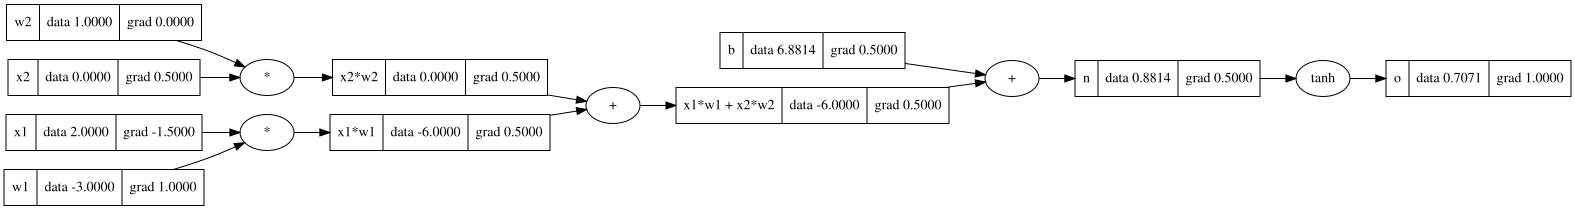

In [ ]:
draw_dot(o)

In [ ]:
o.grad = 1.0

In [ ]:
o._backward()

In [ ]:
n._backward()

In [ ]:
#another way to do thw whole thing using revere toplogical search .

In [ ]:
# now
o.backward

In [ ]:
# Issue, if we use the same variables multiple times in a expression, the gradients are not correct.
#SOLUTION, accumulate the gradients. Sum it up

## Doing the same with PYTORCH

In [1]:
import torch

In [12]:
# Usually leaf node gradients are set to false by default in pytorch so we need to set them. Here we are taking simgle value pytorch arrays( leaf nodes)
# we convert to double to get float64 precision
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())

0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [ ]:
# tensors have a data attribute and a grad attribute like Value class we defined

In [17]:
b.grad.item()

0.5000001283844369

In [116]:
class Value:

  def __init__(self, data, _children=(), _op='', label=''):
    self.data = data
    self.grad = 0.0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"

  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')

    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward

    return out

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')

    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward

    return out

  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')

    def _backward():
        self.grad += other * (self.data ** (other - 1)) * out.grad
    out._backward = _backward

    return out

  def __rmul__(self, other): # other * self
    return self * other

  def __truediv__(self, other): # self / other
    return self * other**-1

  def __neg__(self): # -self
    return self * -1

  def __sub__(self, other): # self - other
    return self + (-other)

  def __radd__(self, other): # other + self
    return self + other

  def tanh(self):
    x = self.data
    t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
    out = Value(t, (self, ), 'tanh')

    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward

    return out

  def exp(self):
    x = self.data
    out = Value(math.exp(x), (self, ), 'exp')

    def _backward():
      self.grad += out.data * out.grad # NOTE: in the video I incorrectly used = instead of +=. Fixed here.
    out._backward = _backward

    return out


  def backward(self):

    topo = []
    visited = set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)

    self.grad = 1.0
    for node in reversed(topo):
      node._backward()

In [117]:
a = [3.0,6.0,9.0]

In [118]:
n1 = Neuron(3)

In [119]:
n1(a)

Value(data=-0.9999999412948549)

In [120]:
l1 = Layer(3,4)
l1(a)

[Value(data=-0.9999999991701393),
 Value(data=0.9996275549996887),
 Value(data=-0.9999996014236044),
 Value(data=0.7425568386777455)]

In [121]:
mlp = MLP(3,[4,4,1])
mlp(a)

Value(data=-0.9560813241526005)

In [122]:
mlp.parameters()

[Value(data=-0.4463572219936003),
 Value(data=-0.20613129796770546),
 Value(data=0.9712811923111089),
 Value(data=0.5189102269048353),
 Value(data=-0.2551827758189211),
 Value(data=-0.8176469689041308),
 Value(data=0.48480927623792547),
 Value(data=0.6723710117474928),
 Value(data=-0.6125285103758309),
 Value(data=-0.7431624558687342),
 Value(data=-0.6453384992222089),
 Value(data=0.7920704759114998),
 Value(data=0.41281670283065375),
 Value(data=0.479342954849562),
 Value(data=-0.27084312474231664),
 Value(data=-0.6646363554722103),
 Value(data=-0.6133008027146916),
 Value(data=0.8048936306005778),
 Value(data=-0.6855268996064969),
 Value(data=0.6552405084516588),
 Value(data=-0.5524742155829467),
 Value(data=-0.2446130476466728),
 Value(data=-0.5533382129032032),
 Value(data=0.2892601648747568),
 Value(data=0.3937266092929581),
 Value(data=0.9423748569205377),
 Value(data=-0.4357681051662188),
 Value(data=-0.6954680927585537),
 Value(data=0.9857063222923466),
 Value(data=-0.537796925

In [123]:
#SOLID EXAMPLE
#what we build above is for one row. Now we need ot build it for 4 rows ( each sample)

In [124]:
xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0] # desired targets

In [125]:
mlp = MLP(3,[4,4,1])
for x in xs:
  print(x)
  print(mlp(x))


[2.0, 3.0, -1.0]
Value(data=-0.23649133019793223)
[3.0, -1.0, 0.5]
Value(data=0.23432411814614965)
[0.5, 1.0, 1.0]
Value(data=-0.25193429284322216)
[1.0, 1.0, -1.0]
Value(data=-0.22902514821954442)


In [126]:
ypred = [mlp(x) for x in xs]

In [127]:
ypred

[Value(data=-0.23649133019793223),
 Value(data=0.23432411814614965),
 Value(data=-0.25193429284322216),
 Value(data=-0.22902514821954442)]

In [128]:
loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))



```
• Negative Gradient: The weights increase (move right).
• Positive Gradient: The weights decrease (move left).

```



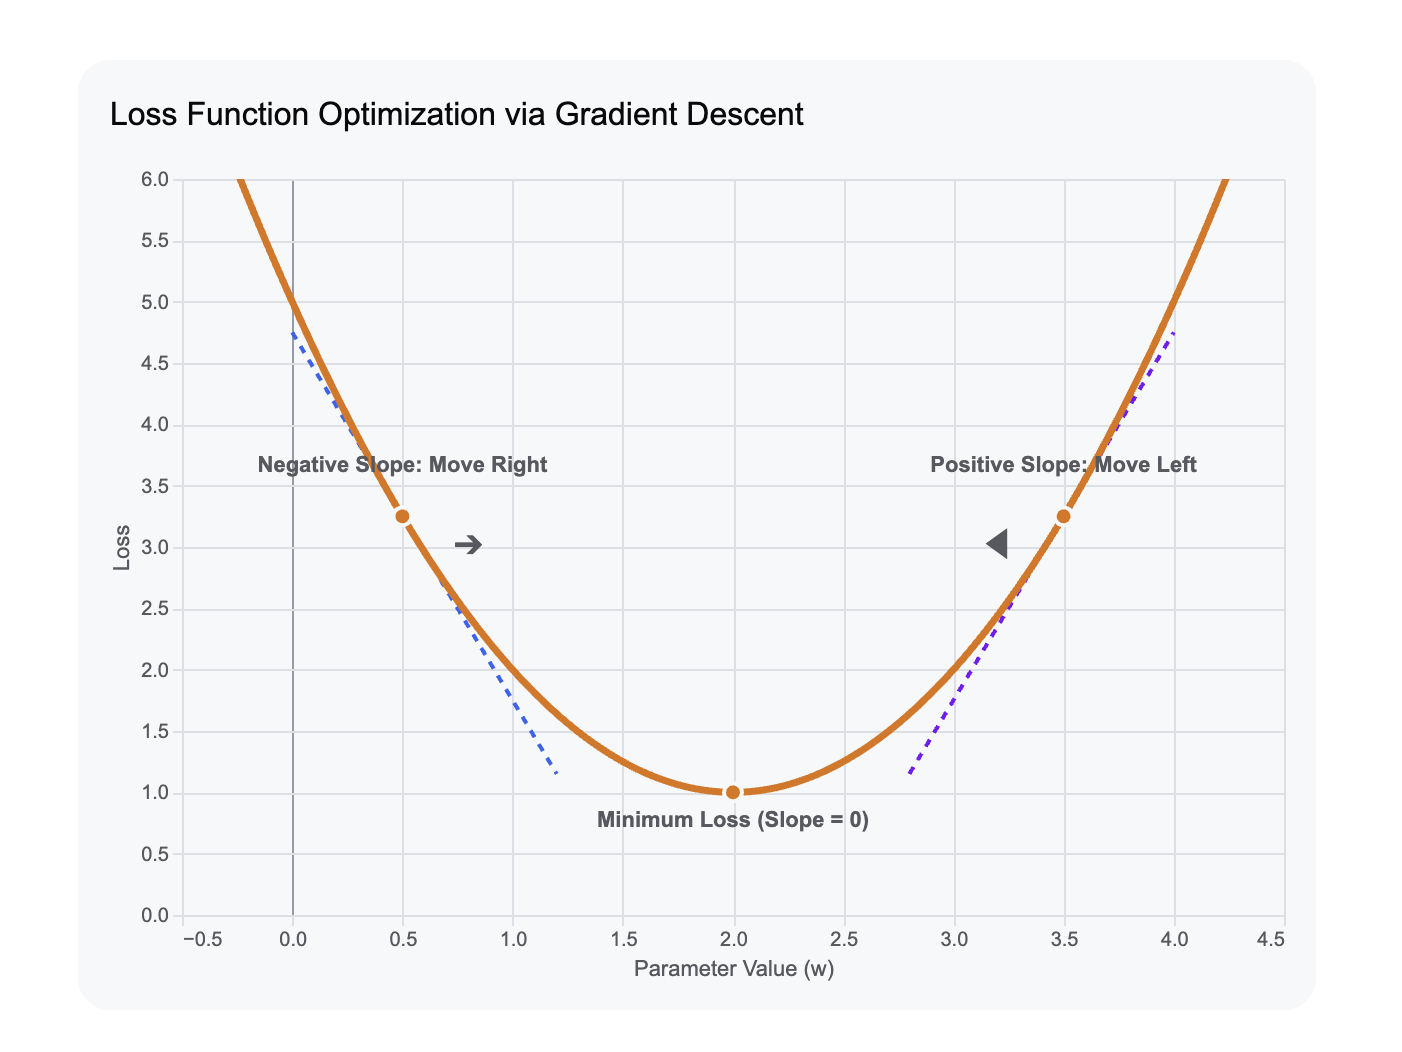

In [ ]:
# SO HERE IS THE LOOP . BACK PROPAGATE. UPDATE weights  BY A BIT AND then you retrain the mlp. Also before any backward pass reset grads to zero

In [129]:
for k in range(20):

  # forward pass
  ypred = [mlp(x) for x in xs]
  loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))

  # backward pass
  for p in mlp.parameters():
    p.grad = 0.0
  loss.backward()

  # update
  for p in mlp.parameters():
    p.data += -0.1 * p.grad

  print(k, loss.data)


0 5.122571955471965
1 2.3310817414161877
2 3.6124986041175835
3 6.053642462305449
4 0.029921220438178533
5 0.027429636481269573
6 0.02537496185670183
7 0.02364141952559859
8 0.022152512060728675
9 0.020855401177731905
10 0.019712229706861283
11 0.018695030730644248
12 0.017782601947173897
13 0.016958510664628244
14 0.01620977697288419
15 0.015525978661588044
16 0.014898626854564811
17 0.014320720358299096
18 0.013786420979996656
19 0.013290812590896935


In [130]:
ypred


[Value(data=0.9428903224429567),
 Value(data=-0.9508454221036419),
 Value(data=-0.9429228212701196),
 Value(data=0.9340051482288533)]